# Fashion MNIST Image Classification with TensorFlow

## Objective
Train a neural network to classify clothing images into one of 10 categories.
Evaluate it on test images and inspect its predictions.

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

## 1. Load the Fashion MNIST Dataset

Fashion MNIST contains 28 × 28 grayscale clothing images. It provides
60,000 training images and 10,000 test images. Each image has a numeric
label from 0 to 9.

In [4]:
# Load Fashion MNIST
fmnist=tf.keras.datasets.fashion_mnist

# Load train and test split
(train_image,train_label), (test_image,test_label)=fmnist.load_data()



## 2. View a Sample Image

Display one training image and its label. The image contains pixel
intensities, with values from 0 to 255.

Label: 3


Raw pixel:
[[  0   0   0   0   0   0   0   0   1   0   0   9   6   0   0   0  24   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  67 209 231 248 252 250 253 246 206
  132   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   1 227 243 234 234 248 246 238 230 234
  250 126   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  57 231 213 227 234 232 231 235 232 218
  218 222   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  90 239 207 213 236 235 232 232 229 210
  215 207   6   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 211 245 229 197 220 221 221 222 203 221
  235 222  96   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  55 154 239 213 217 218 214 215 215 199
  235 167  61   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  17 238 220 221 215 210 249  98
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   2   0 

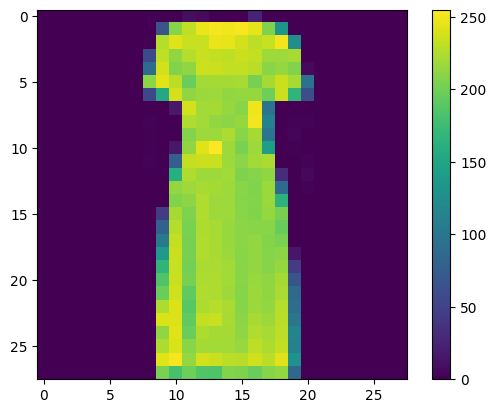

In [5]:
# Change index value
index=50

# print label and the raw pixel value
print(f"Label: {train_label[index]}\n\n\nRaw pixel:\n{train_image[index]} ")
# plot the image
plt.imshow(train_image[index])
plt.colorbar()
plt.show()

## 3. Build and Compile the Model

`Flatten` converts each 28 × 28 image into a one-dimensional list of
784 pixel values. The hidden Dense layer has 128 units and uses ReLU.
The final Dense layer has 10 units—one for each clothing category—and
softmax produces a score for each class.

The model uses the Adam optimizer and sparse categorical cross-entropy
loss. Accuracy is tracked as a metric.

In [6]:
# Normalize pixel values
train_image=train_image/255.0
test_image=test_image/255.0

# Build model
model=tf.keras.models.Sequential([
    tf.keras.Input(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation=tf.nn.relu),
    tf.keras.layers.Dense(10,activation=tf.nn.softmax)
])
# Compile model
model.compile(optimizer=tf.optimizers.Adam(),loss='sparse_categorical_crossentropy',metrics=['accuracy'])



## 4. Train the Model

`model.fit()` trains the model on the training images and their labels.
Here, the model goes through the training data 10 times, or 10 epochs.

In [7]:
# train model
model.fit(train_image,train_label,epochs=10)



Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8229 - loss: 0.5000
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8637 - loss: 0.3775
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8771 - loss: 0.3390
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8845 - loss: 0.3145
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8900 - loss: 0.2974
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8946 - loss: 0.2811
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8996 - loss: 0.2686
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9025 - loss: 0.2609
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9071 - loss: 0.2493
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9109 - loss: 0.2400


## 5. Evaluate the Model

Evaluate the trained model on the test images, which were not used for
training. This reports the test loss and accuracy.

In [8]:
# evaluate on test data
model.evaluate(test_image,test_label)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8798 - loss: 0.3385


[0.33851128816604614, 0.879800021648407]

## 6. Inspect a Prediction

`model.predict(test_image)` produces class scores for every test image.
`classification[0]` shows the scores for the first image. The class with
the highest score is the model’s prediction; compare it with
`test_label[0]`, the true label.

In [9]:
# get what is the model prediction for each class for test image 1
classification=model.predict(test_image)
print(f"Each label prediction for first test image: {classification[0]} ")

predicted_class = classification[0].argmax()
print(f"Predicted class: {predicted_class}")
print(f"Actual class: {test_label[0]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step
Each label prediction for first test image: [1.7157644e-08 4.3388123e-12 5.1012550e-09 5.8400389e-11 7.4721427e-08
 1.2508641e-03 3.4907706e-09 5.5793407e-03 8.8484271e-08 9.9316955e-01] 
Predicted class: 9
Actual class: 9
